# Eliminación del estado transitorio

Cuando la simulación arranca, los cajeros están vacíos, y eso no es lo normal en un parqueadero. Los primeros minutos casi no hay fila y después se va llenando hasta quedar más o menos estable. Ese primer tramo es el **estado transitorio**, y si lo dejamos nos baja los promedios. Aquí buscamos hasta dónde llega y lo quitamos.

**Cómo usar este cuaderno:** ejecuta todas las celdas en orden (botón *Ejecutar todo*). No hay que cambiar nada.

## Paso 1. Datos del problema

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import os

os.makedirs("figuras", exist_ok=True)   # aquí se guardan las gráficas

# Datos del enunciado (cada posición es un tipo de usuario)
prop     = np.array([0.25, 0.20, 0.275, 0.275])   # rápido, normal, lento, muy lento
serv_med = np.array([1, 3, 4, 6])                 # minutos de servicio
lleg_med = np.array([3, 3, 5, 7])                 # minutos entre llegadas

# Tiempo medio entre llegadas que le toca a cada cajero (promedio ponderado)
llegada_cajero = (prop * lleg_med).sum()
print("Intervalo medio entre llegadas por cajero:", llegada_cajero, "min")

HORIZONTE = 6000   # minutos que dura cada simulación

Intervalo medio entre llegadas por cajero: 4.65 min


## Paso 2. Simular un cajero

In [2]:
def un_cajero(rng, horizonte=HORIZONTE):
    # Cuántos carros pueden llegar en 6000 min (le sumo un colchón por si acaso)
    cantidad = int(horizonte / llegada_cajero * 1.3) + 50

    # Cada llegada es la anterior más un tiempo aleatorio; por eso uso cumsum
    hora_llegada = np.cumsum(rng.exponential(llegada_cajero, cantidad))
    hora_llegada = hora_llegada[hora_llegada < horizonte]   # me quedo con los que llegan antes de que termine

    # A cada carro le toca un tipo (rápido, normal...) y según el tipo se demora más o menos
    tipo = rng.choice(4, size=len(hora_llegada), p=prop)
    duracion = rng.exponential(serv_med[tipo])

    # Ahora la fila, uno por uno en el orden en que llegaron
    hora_inicio = np.empty(len(hora_llegada))
    hora_salida = np.empty(len(hora_llegada))
    cajero_libre_desde = 0.0
    for i in range(len(hora_llegada)):
        # si el cajero sigue con otro carro, toca esperar a que se desocupe
        hora_inicio[i] = max(hora_llegada[i], cajero_libre_desde)
        hora_salida[i] = hora_inicio[i] + duracion[i]
        cajero_libre_desde = hora_salida[i]
    return hora_llegada, hora_inicio, hora_salida, tipo, duracion

In [3]:
# Prueba: miro los primeros 5 carros de un cajero
rng = np.random.default_rng(1)
hora_llegada, hora_inicio, hora_salida, tipo, duracion = un_cajero(rng)

print("Carros que llegaron a este cajero:", len(hora_llegada))
print(f"{'#':<3}{'llegó':<10}{'empezó':<10}{'salió':<10}{'espera':<8}")
for i in range(5):
    espera = hora_inicio[i] - hora_llegada[i]
    print(f"{i+1:<3}{hora_llegada[i]:<10.2f}{hora_inicio[i]:<10.2f}{hora_salida[i]:<10.2f}{espera:<8.2f}")

Carros que llegaron a este cajero: 1270
#  llegó     empezó    salió     espera  
1  4.99      4.99      5.35      0.00    
2  6.42      6.42      7.18      0.00    
3  31.42     31.42     48.44     0.00    
4  33.12     48.44     53.04     15.32   
5  33.66     53.04     53.45     19.38   


Fíjate en el carro 4: llega en el minuto 33,12 pero el cajero sigue ocupado con el carro 3 hasta el 48,44, así que espera más de 15 minutos.

## Paso 3. Una réplica y contar la fila

In [4]:
def una_replica(rng, n_cajeros=3):
    # una réplica = simular los 3 cajeros, cada uno con su propia fila
    return [un_cajero(rng) for _ in range(n_cajeros)]

def personas_en_cola(replica, minuto):
    total = 0
    for hora_llegada, hora_inicio, hora_salida, tipo, duracion in replica:
        han_llegado = np.searchsorted(hora_llegada, minuto, side="right")    # carros que ya llegaron
        ya_empezaron = np.searchsorted(hora_inicio, minuto, side="right")    # carros que ya pasaron al cajero
        total = total + (han_llegado - ya_empezaron)                         # la diferencia son los que esperan
    return total / len(replica)    # promedio por cajero

In [5]:
rng = np.random.default_rng(1)
replica = una_replica(rng)
print("Fila promedio por cajero en el minuto 100:", personas_en_cola(replica, 100))
print("Fila promedio por cajero en el minuto 3000:", personas_en_cola(replica, 3000))

Fila promedio por cajero en el minuto 100: 3.6666666666666665
Fila promedio por cajero en el minuto 3000: 0.6666666666666666


Una sola réplica tiene mucho ruido (3,67 en un momento y 0,67 en otro). Por eso en Welch se promedian muchas réplicas.

## Paso 4. Gráfica de Welch

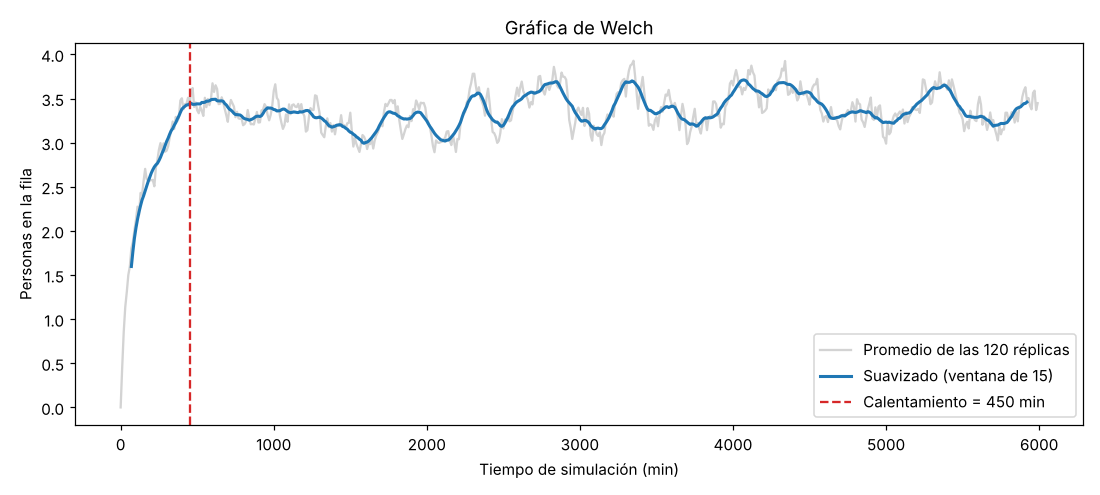

In [6]:
minutos = np.arange(0, HORIZONTE, 10)      # miro la fila cada 10 min
rng = np.random.default_rng(2026)

# 120 réplicas: en cada una anoto cuánta gente había en la fila en cada momento
filas = []
for r in range(120):
    replica = una_replica(rng)
    filas.append(personas_en_cola(replica, minutos))
filas = np.array(filas)
promedio = filas.mean(axis=0)              # promedio de las 120 réplicas

# suavizo con un promedio móvil de 15 puntos para ver mejor la tendencia
ventana = 15
suavizado = np.convolve(promedio, np.ones(ventana)/ventana, mode="same")
suavizado[:ventana//2] = np.nan
suavizado[-(ventana//2):] = np.nan

CALENTAMIENTO = 450

plt.figure(figsize=(10, 4.5))
plt.plot(minutos, promedio, color="lightgray", label="Promedio de las 120 réplicas")
plt.plot(minutos, suavizado, color="tab:blue", linewidth=2, label="Suavizado (ventana de 15)")
plt.axvline(CALENTAMIENTO, color="tab:red", linestyle="--", label="Calentamiento = 450 min")
plt.xlabel("Tiempo de simulación (min)")
plt.ylabel("Personas en la fila")
plt.title("Gráfica de Welch")
plt.legend()
plt.tight_layout()
plt.savefig("figuras/welch.png", dpi=150)
plt.show()

La curva arranca en cero, sube rápido y hacia los 450 minutos llega a la zona donde se queda, oscilando entre 3 y 3,7 personas en la fila. Por eso el calentamiento que usamos es de **450 minutos**.

## Paso 5. Quitar el transitorio: antes y después

Promedio de personas en fila ANTES de quitar el transitorio:   3.368
Promedio de personas en fila DESPUÉS de quitar el transitorio: 3.430


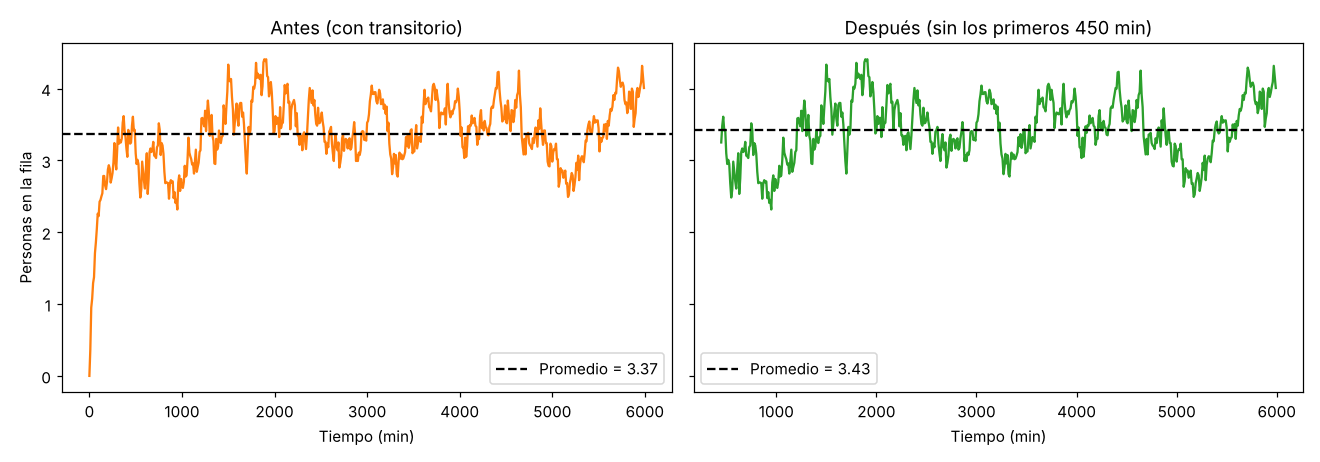

In [7]:
# 40 réplicas para los resultados finales
rng = np.random.default_rng(7)
replicas = [una_replica(rng) for _ in range(40)]
fila_40 = np.array([personas_en_cola(rep, minutos) for rep in replicas]).mean(axis=0)

def eliminar_transitorio(minutos, valores, calentamiento):
    # me quedo solo con lo que pasó después del calentamiento
    quedan = minutos >= calentamiento
    return minutos[quedan], valores[quedan]

min_est, fila_est = eliminar_transitorio(minutos, fila_40, CALENTAMIENTO)

antes = fila_40.mean()
despues = fila_est.mean()
print(f"Promedio de personas en fila ANTES de quitar el transitorio:   {antes:.3f}")
print(f"Promedio de personas en fila DESPUÉS de quitar el transitorio: {despues:.3f}")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)

ejes[0].plot(minutos, fila_40, color="tab:orange")
ejes[0].axhline(antes, color="black", linestyle="--", label=f"Promedio = {antes:.2f}")
ejes[0].set_title("Antes (con transitorio)")
ejes[0].set_xlabel("Tiempo (min)")
ejes[0].set_ylabel("Personas en la fila")
ejes[0].legend()

ejes[1].plot(min_est, fila_est, color="tab:green")
ejes[1].axhline(despues, color="black", linestyle="--", label=f"Promedio = {despues:.2f}")
ejes[1].set_title("Después (sin los primeros 450 min)")
ejes[1].set_xlabel("Tiempo (min)")
ejes[1].legend()

plt.tight_layout()
plt.savefig("figuras/antes_despues.png", dpi=150)
plt.show()

Al quitar los primeros 450 minutos, el promedio sube un poco (de 3,37 a 3,43), porque esos minutos tenían la fila casi vacía. La diferencia es pequeña porque 450 minutos es poco frente a los 6.000 de cada réplica, pero igual conviene quitarlos.

## Paso 6. ¿Importa mucho el 450? ¿Alcanzan 40 réplicas?

In [8]:
def espera_media(replica, calentamiento):
    esperas = []
    for hora_llegada, hora_inicio, hora_salida, tipo, duracion in replica:
        despues_cal = hora_llegada >= calentamiento    # solo los que llegaron después del calentamiento
        esperas.append(hora_inicio[despues_cal] - hora_llegada[despues_cal])
    return np.concatenate(esperas).mean()              # promedio de los 3 cajeros

def intervalo95(datos):
    datos = np.asarray(datos)
    media = datos.mean()
    mitad = stats.t.ppf(0.975, len(datos) - 1) * datos.std(ddof=1) / np.sqrt(len(datos))
    return media, media - mitad, media + mitad

# ¿importa mucho qué calentamiento elija? lo pruebo con varios
print(f"{'Calentamiento':<15}{'Espera media':<15}{'IC 95%'}")
for cal in [0, 150, 300, 450, 600, 900]:
    m, bajo, alto = intervalo95([espera_media(rep, cal) for rep in replicas])
    print(f"{str(cal) + ' min':<15}{m:<15.2f}[{bajo:.2f} ; {alto:.2f}]")

Calentamiento  Espera media   IC 95%
0 min          15.65          [14.70 ; 16.60]
150 min        15.80          [14.82 ; 16.78]
300 min        15.87          [14.88 ; 16.87]
450 min        15.90          [14.90 ; 16.91]
600 min        15.97          [14.93 ; 17.01]
900 min        16.08          [15.01 ; 17.16]


Cambiar el calentamiento de 0 a 900 minutos mueve muy poco la espera media (de 15,6 a 16,1 min). Entonces el 450 no es una elección delicada.

Con 40 réplicas: 15.90 min, IC 95% [14.90 ; 16.91], semiancho relativo 6.3%


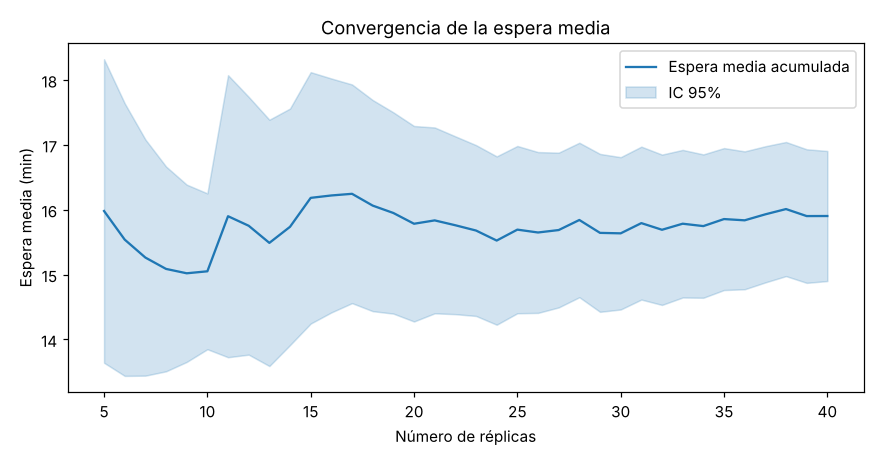

In [9]:
# ¿alcanzan 40 réplicas? miro cómo se cierra el intervalo al ir sumando réplicas
medias = np.array([espera_media(rep, CALENTAMIENTO) for rep in replicas])

n_reps, prom, bajo, alto = [], [], [], []
for k in range(5, 41):
    m, lo, hi = intervalo95(medias[:k])
    n_reps.append(k); prom.append(m); bajo.append(lo); alto.append(hi)

plt.figure(figsize=(8, 4.2))
plt.plot(n_reps, prom, color="tab:blue", label="Espera media acumulada")
plt.fill_between(n_reps, bajo, alto, color="tab:blue", alpha=0.2, label="IC 95%")
plt.xlabel("Número de réplicas")
plt.ylabel("Espera media (min)")
plt.title("Convergencia de la espera media")
plt.legend()
plt.tight_layout()
plt.savefig("figuras/convergencia.png", dpi=150)
plt.show()

m, lo, hi = intervalo95(medias)
print(f"Con 40 réplicas: {m:.2f} min, IC 95% [{lo:.2f} ; {hi:.2f}], semiancho relativo {100*(hi-lo)/2/m:.1f}%")